Assignment 7 - Implement Transfer Learning using pre-trained AlexNet, VGG16, ResNet50 and EfficientNetB0 model for image classification and compare their performance

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries loaded successfully")
print("PyTorch version:", torch.__version__)

Libraries loaded successfully
PyTorch version: 2.11.0+cpu


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Full training images:", len(train_dataset))
print("Full testing images:", len(test_dataset))

 11%|█         | 18.7M/170M [01:51<15:38, 162kB/s]

In [ ]:
# Use a smaller subset for CPU training
train_indices = np.arange(2000)
test_indices = np.arange(1000)

train_subset = Subset(train_dataset, train_indices)
test_subset = Subset(test_dataset, test_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_subset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Training images used:", len(train_subset))
print("Testing images used:", len(test_subset))

Training images used: 2000
Testing images used: 1000


In [ ]:
class_names = train_dataset.classes

print("Classes:")
print(class_names)

Classes:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


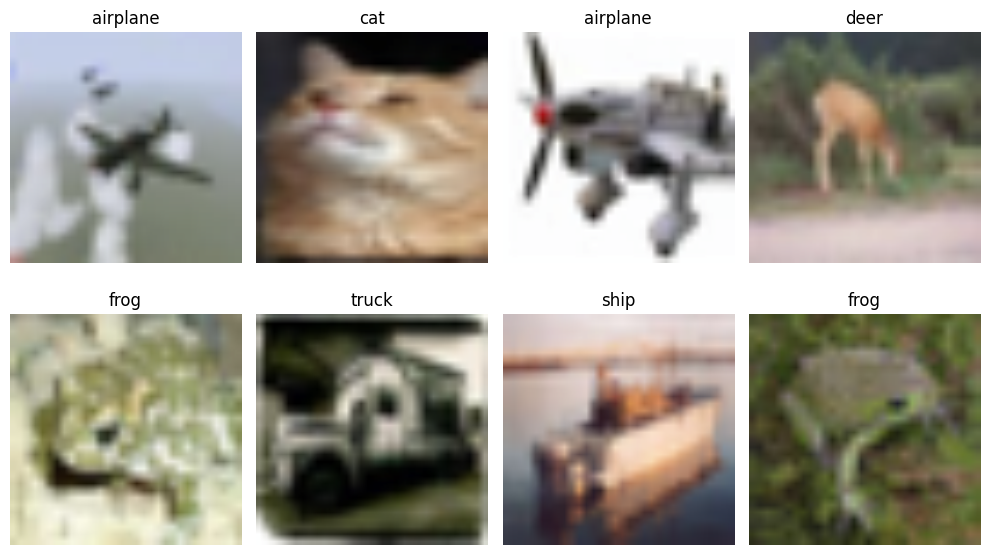

In [ ]:
# Display sample images
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 6))

for i in range(8):
    image = images[i].permute(1, 2, 0).numpy()

    # Undo normalization
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def create_model(model_name):

    if model_name == "AlexNet":

        model = models.alexnet(
            weights=models.AlexNet_Weights.DEFAULT
        )

        # Freeze pretrained layers
        for param in model.parameters():
            param.requires_grad = False

        # Replace classifier
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            10
        )

    elif model_name == "VGG16":

        model = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        # Freeze pretrained layers
        for param in model.parameters():
            param.requires_grad = False

        # Replace classifier
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            10
        )

    elif model_name == "ResNet50":

        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        # Freeze pretrained layers
        for param in model.parameters():
            param.requires_grad = False

        # Replace final layer
        model.fc = nn.Linear(
            model.fc.in_features,
            10
        )

    elif model_name == "EfficientNetB0":

        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        # Freeze pretrained layers
        for param in model.parameters():
            param.requires_grad = False

        # Replace classifier
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            10
        )

    else:
        raise ValueError("Unknown model name")

    return model.to(device)

In [ ]:
def train_model(model, train_loader, test_loader, epochs=2):

    criterion = nn.CrossEntropyLoss()

    # Only train parameters that are not frozen
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.001
    )

    start_time = time.time()

    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} "
            f"- Loss: {epoch_loss:.4f} "
            f"- Accuracy: {epoch_accuracy:.4f}"
        )

    training_time = time.time() - start_time

    # Testing
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = correct / total

    return (
        test_accuracy,
        training_time,
        train_losses,
        train_accuracies
    )

In [ ]:
model_names = [
    "AlexNet",
    "VGG16",
    "ResNet50",
    "EfficientNetB0"
]

results = []

histories = {}

for name in model_names:

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    model = create_model(name)

    test_accuracy, training_time, losses, accuracies = train_model(
        model,
        train_loader,
        test_loader,
        epochs=2
    )

    results.append({
        "Model": name,
        "Accuracy": test_accuracy,
        "Training Time (seconds)": training_time
    })

    histories[name] = {
        "loss": losses,
        "accuracy": accuracies
    }

    print(f"\n{name} Test Accuracy: {test_accuracy:.4f}")
    print(f"{name} Training Time: {training_time:.2f} seconds")


AlexNet
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 151MB/s]


Epoch 1/2 - Loss: 1.0984 - Accuracy: 0.6045
Epoch 2/2 - Loss: 0.6452 - Accuracy: 0.7685

AlexNet Test Accuracy: 0.7360
AlexNet Training Time: 149.82 seconds

VGG16
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:09<00:00, 60.8MB/s]


Epoch 1/2 - Loss: 1.0845 - Accuracy: 0.6400
Epoch 2/2 - Loss: 0.6184 - Accuracy: 0.7865

VGG16 Test Accuracy: 0.7440
VGG16 Training Time: 2790.55 seconds

ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s]


Epoch 1/2 - Loss: 1.7232 - Accuracy: 0.4865
Epoch 2/2 - Loss: 1.1307 - Accuracy: 0.6980

ResNet50 Test Accuracy: 0.6990
ResNet50 Training Time: 1150.35 seconds

EfficientNetB0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 85.1MB/s]


Epoch 1/2 - Loss: 1.8057 - Accuracy: 0.4830
Epoch 2/2 - Loss: 1.2228 - Accuracy: 0.6840

EfficientNetB0 Test Accuracy: 0.7090
EfficientNetB0 Training Time: 427.66 seconds
